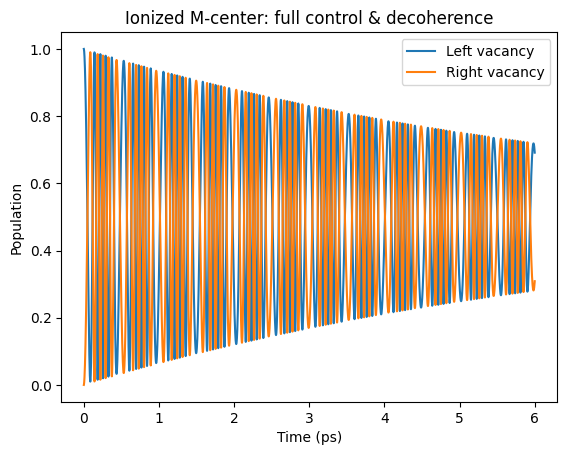

In [2]:
import numpy as np
from scipy.linalg import expm
import matplotlib.pyplot as plt

# ---------- Константы ----------
hbar = 6.582e-16  # eV*s
e = 1.602e-19

# ---------- Параметры ----------
t0 = 0.02         # eV
d = 3e-10         # m
E0 = 5e6          # V/m
A = 0.01          # eV (лазер)
omega_L = 2e12*2*np.pi  # рад/с

Gamma_phi = 1e11  # 1/s
Gamma_1 = 5e10    # 1/s

# ---------- Матрицы ----------
sx = np.array([[0,1],[1,0]],dtype=complex)
sz = np.array([[1,0],[0,-1]],dtype=complex)
sm = np.array([[0,0],[1,0]],dtype=complex)
I = np.eye(2)

# ---------- Управление ----------
def E_field(t):
    return E0 * np.tanh((t-2e-12)/5e-13)

def Delta(t):
    return e * E_field(t) * d / e

def H(t):
    return (
        -t0*sx
        + 0.5*Delta(t)*sz
        + A*np.cos(omega_L*t)*sx
    )

# ---------- Линбладовская часть ----------
def lindblad(rho):
    Dphi = Gamma_phi*(sz@rho@sz - rho)
    D1 = Gamma_1*(sm@rho@sm.conj().T
                  - 0.5*(sm.conj().T@sm@rho + rho@sm.conj().T@sm))
    return Dphi + D1

# ---------- Эволюция ----------
dt = 1e-15
T = 6e-12
N = int(T/dt)

rho = np.array([[1,0],[0,0]],dtype=complex)

time, PL, PR = [], [], []

for i in range(N):
    t = i*dt
    U = expm(-1j*H(t)*dt/hbar)
    rho = U@rho@U.conj().T + lindblad(rho)*dt
    rho /= np.trace(rho)

    time.append(t)
    PL.append(np.real(rho[0,0]))
    PR.append(np.real(rho[1,1]))

# ---------- График ----------
plt.plot(np.array(time)*1e12, PL, label='Left vacancy')
plt.plot(np.array(time)*1e12, PR, label='Right vacancy')
plt.xlabel("Time (ps)")
plt.ylabel("Population")
plt.legend()
plt.title("Ionized M-center: full control & decoherence")
plt.show()


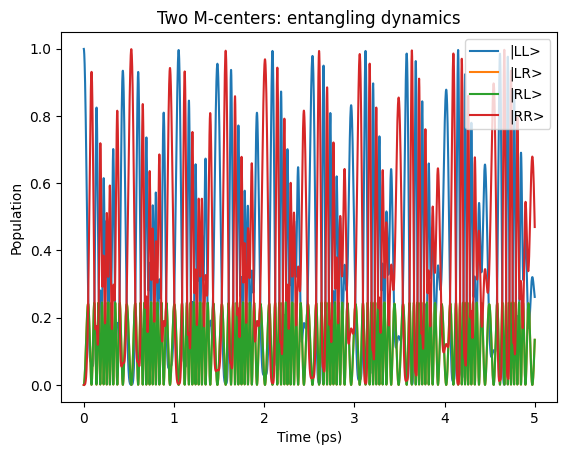

In [3]:
import numpy as np
from scipy.linalg import expm
import matplotlib.pyplot as plt

# ---------- Константы ----------
hbar = 6.582e-16  # eV*s

# ---------- Параметры ----------
t1 = t2 = 0.02     # eV
J = 0.004          # eV (межкубитная связь)

A1 = A2 = 0.01     # лазер
omega = 2*np.pi*2e12

# ---------- Матрицы Паули ----------
sx = np.array([[0,1],[1,0]],dtype=complex)
sz = np.array([[1,0],[0,-1]],dtype=complex)
I = np.eye(2)

# ---------- Тензорные операторы ----------
sx1 = np.kron(sx, I)
sx2 = np.kron(I, sx)
sz1 = np.kron(sz, I)
sz2 = np.kron(I, sz)
ZZ  = np.kron(sz, sz)

# ---------- Управление ----------
def Delta1(t): return 0.0
def Delta2(t): return 0.0

def H(t):
    return (
        -t1*sx1 - t2*sx2
        + 0.5*Delta1(t)*sz1
        + 0.5*Delta2(t)*sz2
        + A1*np.cos(omega*t)*sx1
        + A2*np.cos(omega*t)*sx2
        + J*ZZ
    )

# ---------- Временная эволюция ----------
dt = 1e-15
T = 5e-12
N = int(T/dt)

# начальное состояние |LL>
psi = np.array([1,0,0,0],dtype=complex)

# запись
pop = []

for i in range(N):
    t = i*dt
    U = expm(-1j*H(t)*dt/hbar)
    psi = U @ psi
    psi /= np.linalg.norm(psi)
    pop.append(np.abs(psi)**2)

pop = np.array(pop)
time = np.linspace(0,T,N)*1e12

# ---------- График ----------
plt.plot(time, pop[:,0], label='|LL>')
plt.plot(time, pop[:,1], label='|LR>')
plt.plot(time, pop[:,2], label='|RL>')
plt.plot(time, pop[:,3], label='|RR>')
plt.xlabel("Time (ps)")
plt.ylabel("Population")
plt.legend()
plt.title("Two M-centers: entangling dynamics")
plt.show()


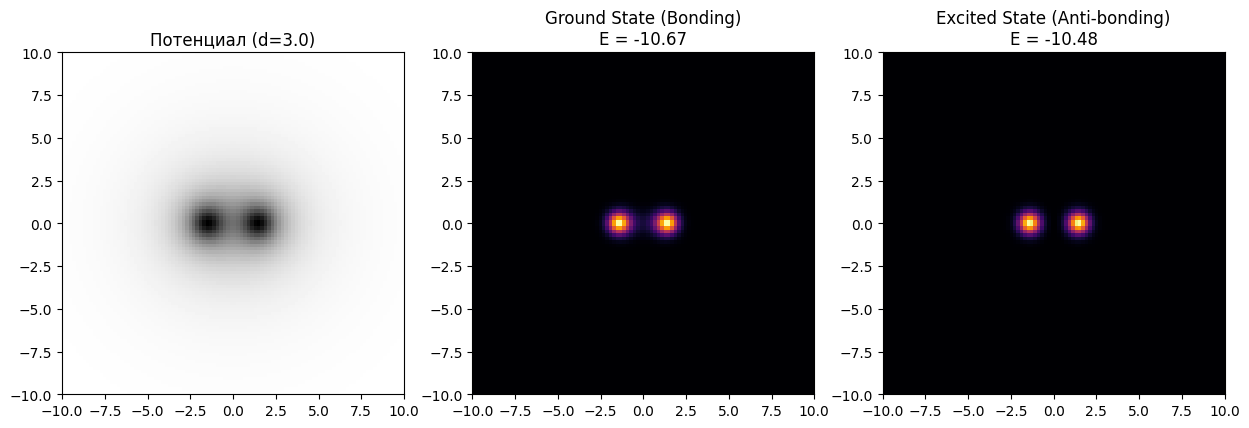

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import eigsh

def solve_double_well_2d(dist, N=100, L=20, E_field=0):
    """
    dist: расстояние между центрами ям
    N: разрешение сетки (NxN)
    L: физический размер области
    E_field: внешнее электрическое поле (вдоль оси X)
    """
    x = np.linspace(-L/2, L/2, N)
    y = np.linspace(-L/2, L/2, N)
    X, Y = np.meshgrid(x, y)
    
    # Шаг сетки
    h = x[1] - x[0]
    
    # 1. Создаем потенциал двух ям (Лоренцев или Гауссов вид для мягкости)
    # Яма 1 (слева)
    R1 = np.sqrt((X + dist/2)**2 + Y**2)
    V1 = -15.0 / (1 + R1**2) # Глубина и форма условные
    
    # Яма 2 (справа)
    R2 = np.sqrt((X - dist/2)**2 + Y**2)
    V2 = -15.0 / (1 + R2**2)
    
    # Внешнее поле (Stark effect): V = e*E*x
    V_stark = - E_field * X 
    
    V_total = V1 + V2 + V_stark
    
    # 2. Собираем Гамильтониан для 2D (Лапласиан по 5 точкам)
    # H = - (d2/dx2 + d2/dy2) + V
    # В матричном виде для вектора psi (развернутого в 1D массив длины N^2)
    
    # Диагонали для лапласиана
    ones = np.ones(N*N)
    main_diag = 4.0 * ones / h**2 + V_total.flatten()
    off_diag_x = -1.0 * ones / h**2
    off_diag_y = -1.0 * ones / h**2
    
    # Нюанс: off_diag_x нужно обнулять на границах строк, но для простой задачи
    # с нулевыми граничными условиями и большим ящиком этим можно пренебречь или использовать scipy.sparse.kron
    
    # Правильная сборка через kron (более надежно для студента)
    from scipy.sparse import kron, eye
    I = eye(N)
    D2 = diags([-1, 2, -1], [-1, 0, 1], shape=(N, N)) / h**2
    Laplacian = kron(I, D2) + kron(D2, I) # Dxx + Dyy
    
    H = Laplacian + diags(V_total.flatten(), 0)
    
    # 3. Решаем
    vals, vecs = eigsh(H, k=2, which='SA') # Ищем 2 нижних уровня
    
    # Возвращаем энергии и волновые функции (решейпнутые обратно в 2D)
    psi_ground = vecs[:, 0].reshape((N, N))
    psi_excited = vecs[:, 1].reshape((N, N))
    
    return vals, psi_ground, psi_excited, V_total

# --- ЗАДАНИЕ ДЛЯ СТУДЕНТА: ИССЛЕДОВАНИЕ ---

# Сценарий 1: Сильное взаимодействие (ямы близко)
dist_close = 3.0
E, psi0, psi1, V = solve_double_well_2d(dist=dist_close)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(V, extent=[-10,10,-10,10], cmap='gray')
ax[0].set_title(f"Потенциал (d={dist_close})")

ax[1].imshow(psi0**2, extent=[-10,10,-10,10], cmap='inferno')
ax[1].set_title(f"Ground State (Bonding)\nE = {E[0]:.2f}")

ax[2].imshow(psi1**2, extent=[-10,10,-10,10], cmap='inferno')
ax[2].set_title(f"Excited State (Anti-bonding)\nE = {E[1]:.2f}")
plt.show()

# Сценарий 2: Включение поля (Локализация)
# Попроси студента увеличить E_field и посмотреть, как psi0 сместится в одну яму.

Eigenenergies:
0 0.41240672437242787
1 1.0019805098768892
2 1.0019805098768997
3 1.0019805098769137
4 1.5898679084285572
5 1.589867908428598


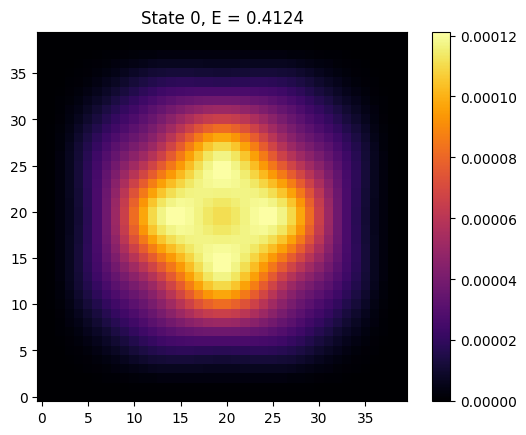

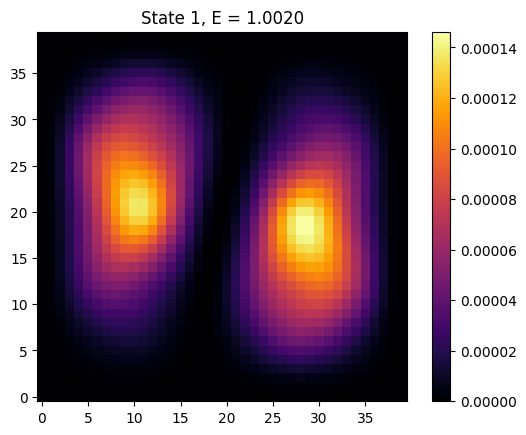

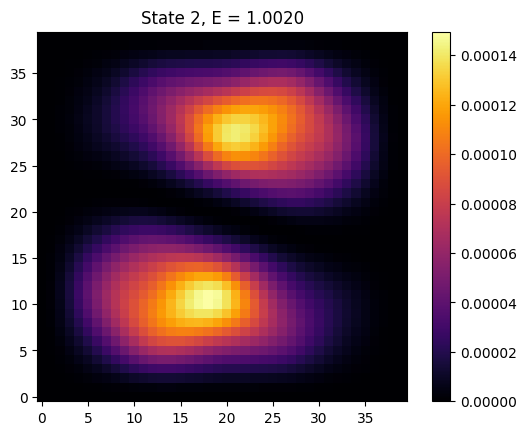

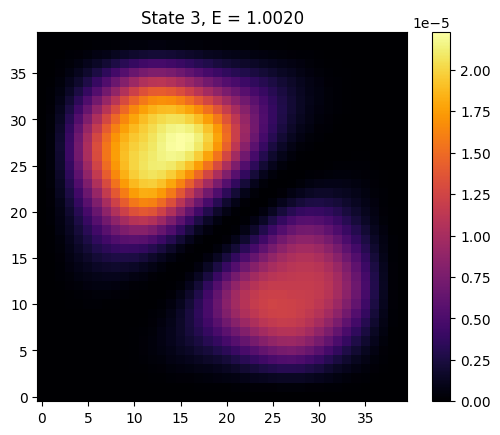


Dipole moments of transverse states:
State 2: <x>=-0.00000, <y>=0.00000, <z>=-0.00000
State 3: <x>=-0.00000, <y>=-0.00000, <z>=-0.00000


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import eigsh

a = 1.0
q = 1.0
delta = 0.3

Nx = Ny = Nz = 40
L = 5 * a

x = np.linspace(-L/2, L/2, Nx)
y = np.linspace(-L/2, L/2, Ny)
z = np.linspace(-L/2, L/2, Nz)
h = x[1] - x[0]

def generate_ionic_lattice(n_cells=3):
    ions = []
    for i in range(-n_cells, n_cells+1):
        for j in range(-n_cells, n_cells+1):
            for k in range(-n_cells, n_cells+1):
                r = np.array([i, j, k]) * a
                if (i + j + k) % 2 == 0:
                    ions.append((r, +q))
                else:
                    ions.append((r, -q))
    return ions

ions = generate_ionic_lattice()

vac1 = np.array([0, 0, 0])
vac2 = np.array([a, a, 0])

def is_vacancy(r):
    return np.allclose(r, vac1) or np.allclose(r, vac2)

ions_defect = []
for r, charge in ions:
    if charge < 0 and is_vacancy(r):
        continue
    ions_defect.append((r, charge))

V = np.zeros((Nx, Ny, Nz))

for ix, X in enumerate(x):
    for iy, Y in enumerate(y):
        for iz, Z in enumerate(z):
            R = np.array([X, Y, Z])
            pot = 0.0
            for r_ion, q_ion in ions_defect:
                d = np.linalg.norm(R - r_ion)
                pot += q_ion / np.sqrt(d*d + delta*delta)
            V[ix, iy, iz] = pot

def idx(i, j, k):
    return i + Nx * (j + Ny * k)

N = Nx * Ny * Nz
H = lil_matrix((N, N))

coef = 1.0 / h**2

for i in range(1, Nx-1):
    for j in range(1, Ny-1):
        for k in range(1, Nz-1):
            p = idx(i, j, k)
            H[p, p] = 3*coef + V[i, j, k]
            H[p, idx(i+1, j, k)] = -0.5*coef
            H[p, idx(i-1, j, k)] = -0.5*coef
            H[p, idx(i, j+1, k)] = -0.5*coef
            H[p, idx(i, j-1, k)] = -0.5*coef
            H[p, idx(i, j, k+1)] = -0.5*coef
            H[p, idx(i, j, k-1)] = -0.5*coef

H = csr_matrix(H)

n_states = 6
energies, states = eigsh(H, k=n_states, which='SA')

print("Eigenenergies:")
for i, E in enumerate(energies):
    print(i, E)

def plot_slice(psi, title):
    psi3d = psi.reshape((Nx, Ny, Nz))
    mid = Nz // 2
    plt.imshow(psi3d[:, :, mid]**2, origin='lower', cmap='inferno')
    plt.colorbar()
    plt.title(title)
    plt.show()

for n in range(4):
    plot_slice(states[:, n], f"State {n}, E = {energies[n]:.4f}")

def dipole_expectation(psi, axis):
    psi3d = psi.reshape((Nx, Ny, Nz))
    if axis == 'x':
        coord = x[:, None, None]
    elif axis == 'y':
        coord = y[None, :, None]
    else:
        coord = z[None, None, :]
    return np.sum(coord * psi3d**2)

print("\nDipole moments of transverse states:")
for n in [2, 3]:
    dx = dipole_expectation(states[:, n], 'x')
    dy = dipole_expectation(states[:, n], 'y')
    dz = dipole_expectation(states[:, n], 'z')
    print(f"State {n}: <x>={dx:.5f}, <y>={dy:.5f}, <z>={dz:.5f}")


Eigenenergies:
0 0.41240672437244885
1 1.0019805098768526
2 1.0019805098768853
3 1.001980509876976
4 1.5898679084285776
5 1.5898679084286127


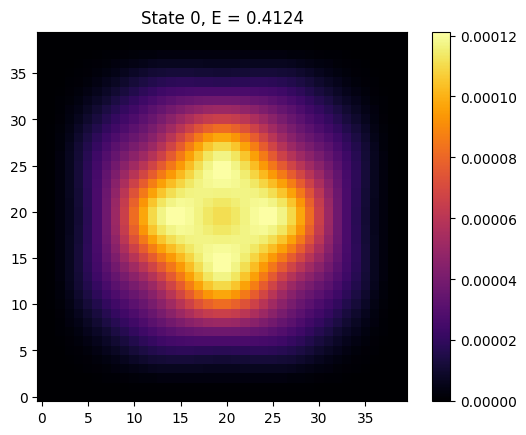

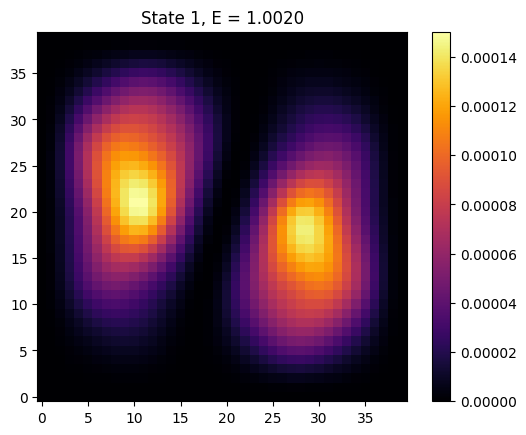

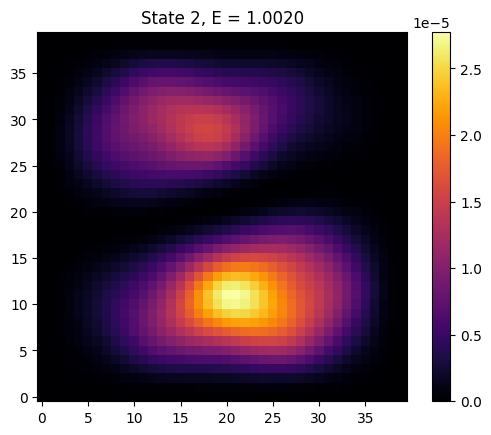

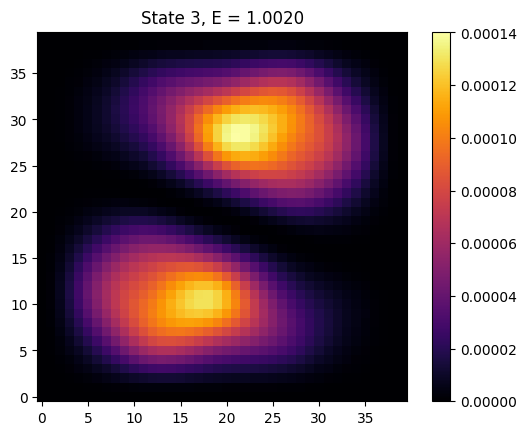

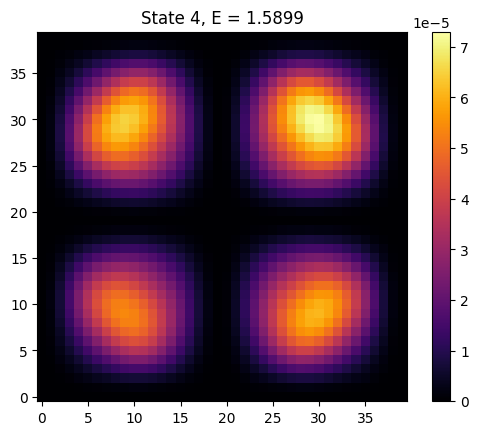

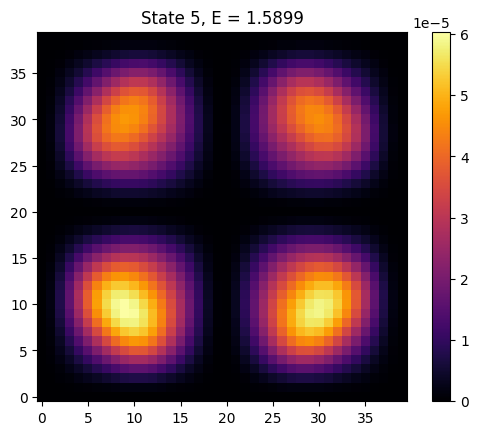


Dipole moments of transverse states:
State 2: <x>=-0.00000, <y>=-0.00000, <z>=-0.00000
State 3: <x>=-0.00000, <y>=-0.00000, <z>=0.00000


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import eigsh

a = 1.0
q = 1.0
delta = 0.3

Nx = Ny = Nz = 40
L = 5 * a

x = np.linspace(-L/2, L/2, Nx)
y = np.linspace(-L/2, L/2, Ny)
z = np.linspace(-L/2, L/2, Nz)
h = x[1] - x[0]

def generate_ionic_lattice(n_cells=3):
    ions = []
    for i in range(-n_cells, n_cells+1):
        for j in range(-n_cells, n_cells+1):
            for k in range(-n_cells, n_cells+1):
                r = np.array([i, j, k]) * a
                if (i + j + k) % 2 == 0:
                    ions.append((r, +q))
                else:
                    ions.append((r, -q))
    return ions

ions = generate_ionic_lattice()

vac1 = np.array([0, 0, 0])
vac2 = np.array([a, a, 0])

def is_vacancy(r):
    return np.allclose(r, vac1) or np.allclose(r, vac2)

ions_defect = []
for r, charge in ions:
    if charge < 0 and is_vacancy(r):
        continue
    ions_defect.append((r, charge))

V = np.zeros((Nx, Ny, Nz))

for ix, X in enumerate(x):
    for iy, Y in enumerate(y):
        for iz, Z in enumerate(z):
            R = np.array([X, Y, Z])
            pot = 0.0
            for r_ion, q_ion in ions_defect:
                d = np.linalg.norm(R - r_ion)
                pot += q_ion / np.sqrt(d*d + delta*delta)
            V[ix, iy, iz] = pot

def idx(i, j, k):
    return i + Nx * (j + Ny * k)

N = Nx * Ny * Nz
H = lil_matrix((N, N))

coef = 1.0 / h**2

for i in range(1, Nx-1):
    for j in range(1, Ny-1):
        for k in range(1, Nz-1):
            p = idx(i, j, k)
            H[p, p] = 3*coef + V[i, j, k]
            H[p, idx(i+1, j, k)] = -0.5*coef
            H[p, idx(i-1, j, k)] = -0.5*coef
            H[p, idx(i, j+1, k)] = -0.5*coef
            H[p, idx(i, j-1, k)] = -0.5*coef
            H[p, idx(i, j, k+1)] = -0.5*coef
            H[p, idx(i, j, k-1)] = -0.5*coef

H = csr_matrix(H)

n_states = 6
energies, states = eigsh(H, k=n_states, which='SA')

print("Eigenenergies:")
for i, E in enumerate(energies):
    print(i, E)

def plot_slice(psi, title):
    psi3d = psi.reshape((Nx, Ny, Nz))
    mid = Nz // 2
    plt.imshow(psi3d[:, :, mid]**2, origin='lower', cmap='inferno')
    plt.colorbar()
    plt.title(title)
    plt.show()

for n in range(6):
    plot_slice(states[:, n], f"State {n}, E = {energies[n]:.4f}")

def dipole_expectation(psi, axis):
    psi3d = psi.reshape((Nx, Ny, Nz))
    if axis == 'x':
        coord = x[:, None, None]
    elif axis == 'y':
        coord = y[None, :, None]
    else:
        coord = z[None, None, :]
    return np.sum(coord * psi3d**2)

print("\nDipole moments of transverse states:")
for n in [2, 3]:
    dx = dipole_expectation(states[:, n], 'x')
    dy = dipole_expectation(states[:, n], 'y')
    dz = dipole_expectation(states[:, n], 'z')
    print(f"State {n}: <x>={dx:.5f}, <y>={dy:.5f}, <z>={dz:.5f}")


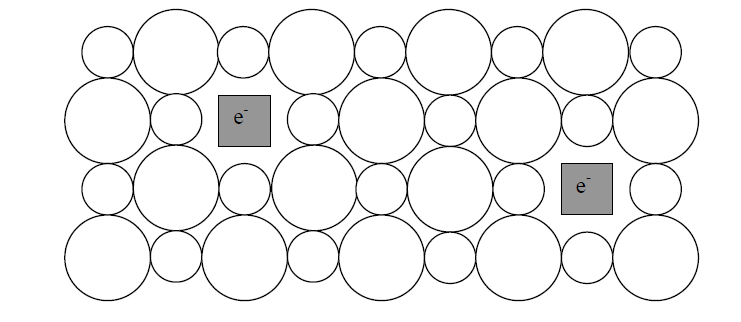

Eigenenergies:
0 0.39329968856707687
1 0.9817915620236779
2 0.9817915620237275
3 0.9817915620238323
4 1.5676020950774572
5 1.5676020950774614


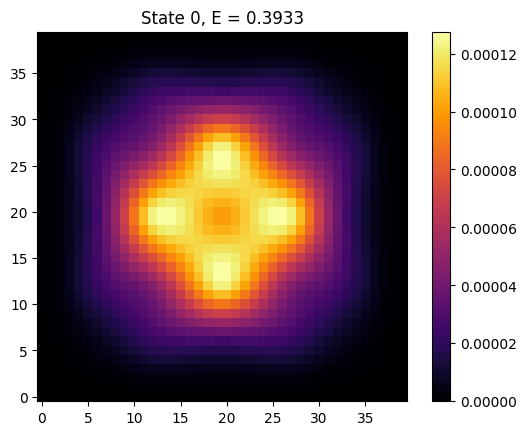

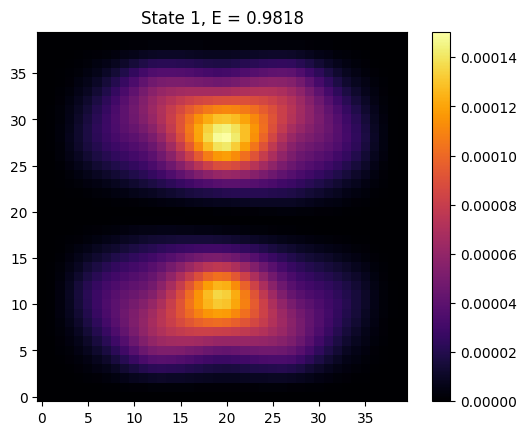

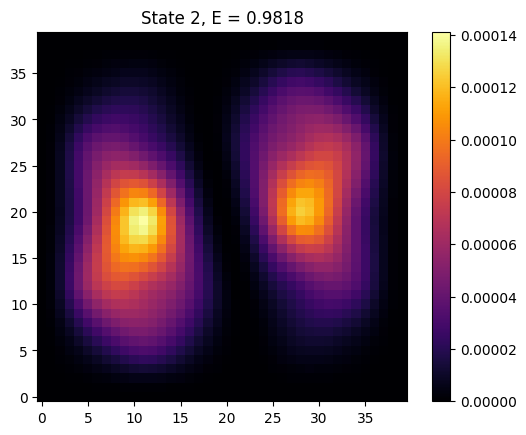

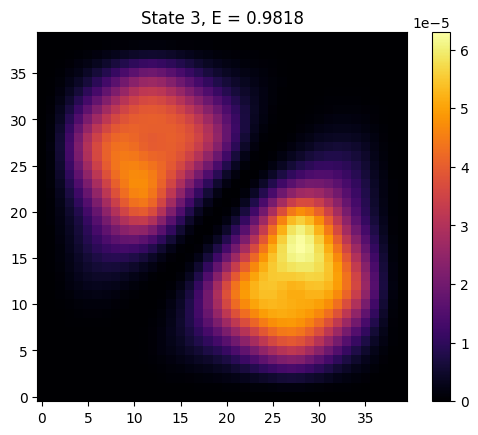

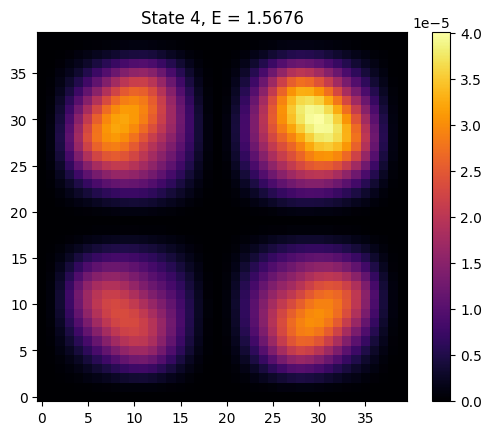

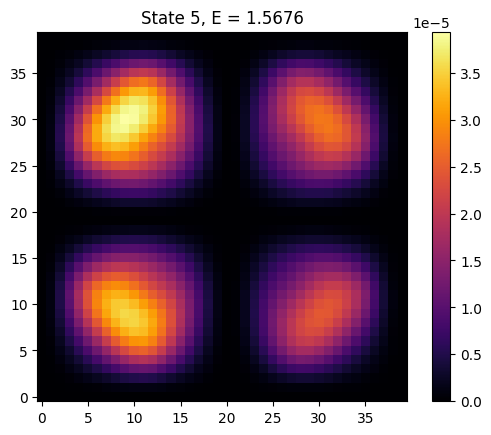


Dipole moments of transverse states:
State 2: <x>=0.00000, <y>=0.00000, <z>=-0.00000
State 3: <x>=-0.00000, <y>=0.00000, <z>=0.00000


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import eigsh

a = 1.0
q = 1.0
delta = 0.2

Nx = Ny = Nz = 40
L = 5 * a

x = np.linspace(-L/2, L/2, Nx)
y = np.linspace(-L/2, L/2, Ny)
z = np.linspace(-L/2, L/2, Nz)
h = x[1] - x[0]

def generate_ionic_lattice(n_cells=3):
    ions = []
    for i in range(-n_cells, n_cells+1):
        for j in range(-n_cells, n_cells+1):
            for k in range(-n_cells, n_cells+1):
                r = np.array([i, j, k]) * a
                if (i + j + k) % 2 == 0:
                    ions.append((r, +q))
                else:
                    ions.append((r, -q))
    return ions

ions = generate_ionic_lattice()

vac1 = np.array([0, 0, 0])
vac2 = np.array([a, a, 0])

def is_vacancy(r):
    return np.allclose(r, vac1) or np.allclose(r, vac2)

ions_defect = []
for r, charge in ions:
    if charge < 0 and is_vacancy(r):
        continue
    ions_defect.append((r, charge))

V = np.zeros((Nx, Ny, Nz))

for ix, X in enumerate(x):
    for iy, Y in enumerate(y):
        for iz, Z in enumerate(z):
            R = np.array([X, Y, Z])
            pot = 0.0
            for r_ion, q_ion in ions_defect:
                d = np.linalg.norm(R - r_ion)
                pot += q_ion / np.sqrt(d*d + delta*delta)
            V[ix, iy, iz] = pot

def idx(i, j, k):
    return i + Nx * (j + Ny * k)

N = Nx * Ny * Nz
H = lil_matrix((N, N))

coef = 1.0 / h**2

for i in range(1, Nx-1):
    for j in range(1, Ny-1):
        for k in range(1, Nz-1):
            p = idx(i, j, k)
            H[p, p] = 3*coef + V[i, j, k]
            H[p, idx(i+1, j, k)] = -0.5*coef
            H[p, idx(i-1, j, k)] = -0.5*coef
            H[p, idx(i, j+1, k)] = -0.5*coef
            H[p, idx(i, j-1, k)] = -0.5*coef
            H[p, idx(i, j, k+1)] = -0.5*coef
            H[p, idx(i, j, k-1)] = -0.5*coef

H = csr_matrix(H)

n_states = 6
energies, states = eigsh(H, k=n_states, which='SA')

print("Eigenenergies:")
for i, E in enumerate(energies):
    print(i, E)

def plot_slice(psi, title):
    psi3d = psi.reshape((Nx, Ny, Nz))
    mid = Nz // 2
    plt.imshow(psi3d[:, :, mid]**2, origin='lower', cmap='inferno')
    plt.colorbar()
    plt.title(title)
    plt.show()

for n in range(6):
    plot_slice(states[:, n], f"State {n}, E = {energies[n]:.4f}")

def dipole_expectation(psi, axis):
    psi3d = psi.reshape((Nx, Ny, Nz))
    if axis == 'x':
        coord = x[:, None, None]
    elif axis == 'y':
        coord = y[None, :, None]
    else:
        coord = z[None, None, :]
    return np.sum(coord * psi3d**2)

print("\nDipole moments of transverse states:")
for n in [2, 3]:
    dx = dipole_expectation(states[:, n], 'x')
    dy = dipole_expectation(states[:, n], 'y')
    dz = dipole_expectation(states[:, n], 'z')
    print(f"State {n}: <x>={dx:.5f}, <y>={dy:.5f}, <z>={dz:.5f}")


Eigenenergies:
0 0.393299688567082
1 0.9817915620236957
2 0.9817915620237586
3 0.9817915620237747
4 1.5676020950774183
5 1.5676020950774534


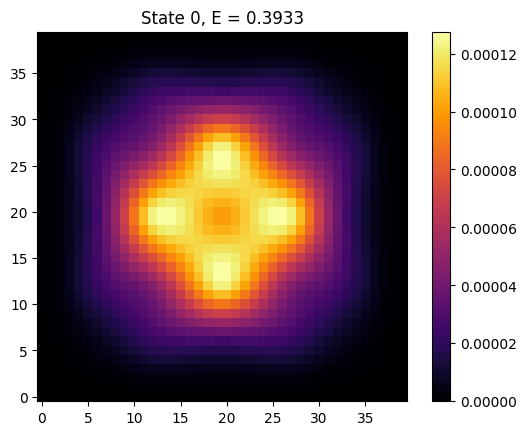

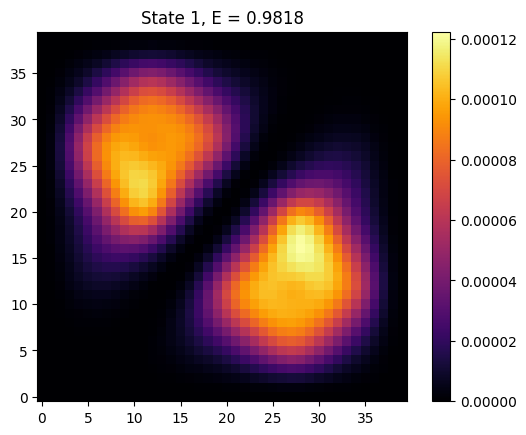

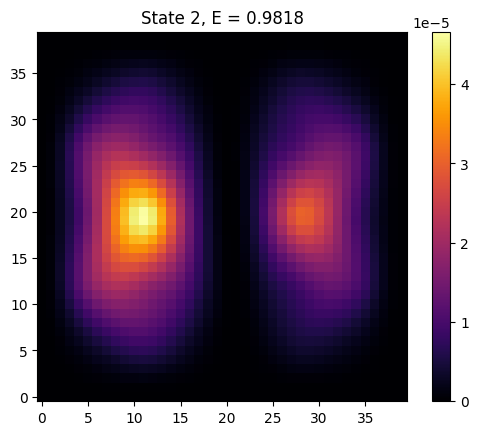

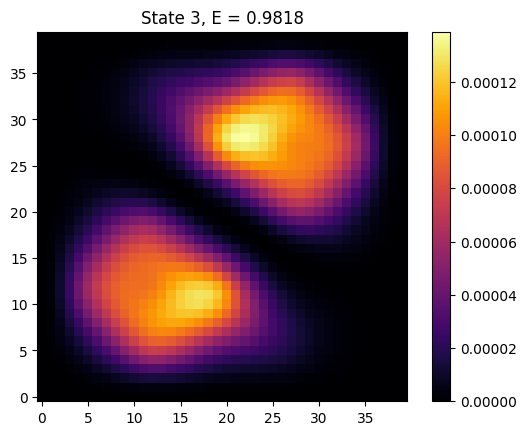

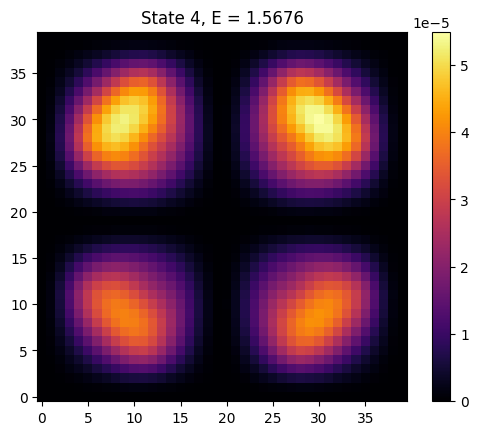

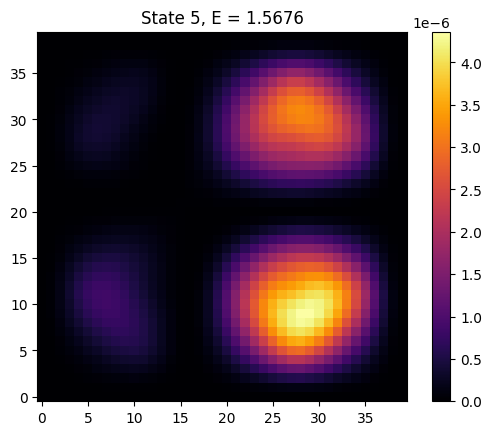


Dipole moments of transverse states:
State 2: <x>=-0.00000, <y>=-0.00000, <z>=-0.00000
State 3: <x>=-0.00000, <y>=-0.00000, <z>=-0.00000

Zeeman-split energies of transverse states:
State 0: E = 0.1000
State 1: E = 0.1000
State 2: E = 0.1000


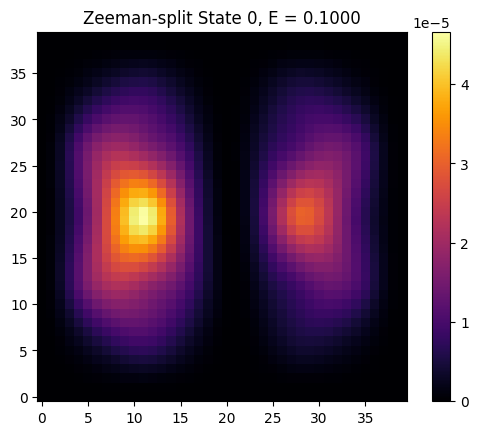

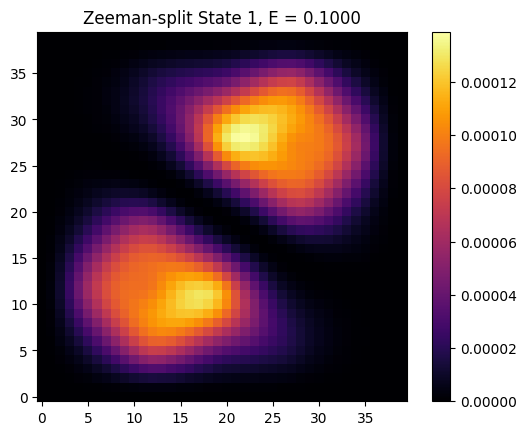

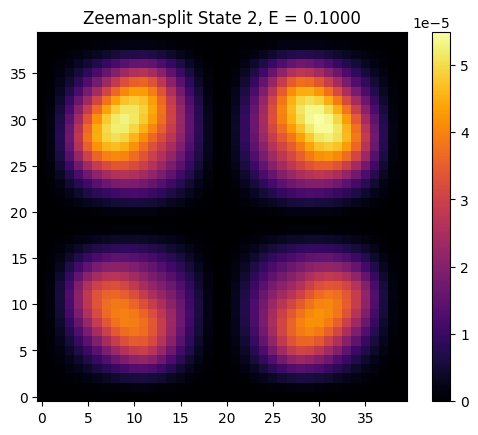

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import eigsh

# ----------------------------
# Параметры решётки и дефекта
# ----------------------------
a = 1.0
q = 1.0
delta = 0.2

Nx = Ny = Nz = 40
L = 5 * a

x = np.linspace(-L/2, L/2, Nx)
y = np.linspace(-L/2, L/2, Ny)
z = np.linspace(-L/2, L/2, Nz)
h = x[1] - x[0]

def generate_ionic_lattice(n_cells=3):
    ions = []
    for i in range(-n_cells, n_cells+1):
        for j in range(-n_cells, n_cells+1):
            for k in range(-n_cells, n_cells+1):
                r = np.array([i, j, k]) * a
                if (i + j + k) % 2 == 0:
                    ions.append((r, +q))
                else:
                    ions.append((r, -q))
    return ions

ions = generate_ionic_lattice()

vac1 = np.array([0, 0, 0])
vac2 = np.array([a, a, 0])

def is_vacancy(r):
    return np.allclose(r, vac1) or np.allclose(r, vac2)

ions_defect = []
for r, charge in ions:
    if charge < 0 and is_vacancy(r):
        continue
    ions_defect.append((r, charge))

# ----------------------------
# Потенциал на сетке
# ----------------------------
V = np.zeros((Nx, Ny, Nz))

for ix, X in enumerate(x):
    for iy, Y in enumerate(y):
        for iz, Z in enumerate(z):
            R = np.array([X, Y, Z])
            pot = 0.0
            for r_ion, q_ion in ions_defect:
                d = np.linalg.norm(R - r_ion)
                pot += q_ion / np.sqrt(d*d + delta*delta)
            V[ix, iy, iz] = pot

# ----------------------------
# Индексация и гамильтониан
# ----------------------------
def idx(i, j, k):
    return i + Nx * (j + Ny * k)

N = Nx * Ny * Nz
H = lil_matrix((N, N))

coef = 1.0 / h**2

for i in range(1, Nx-1):
    for j in range(1, Ny-1):
        for k in range(1, Nz-1):
            p = idx(i, j, k)
            H[p, p] = 3*coef + V[i, j, k]
            H[p, idx(i+1, j, k)] = -0.5*coef
            H[p, idx(i-1, j, k)] = -0.5*coef
            H[p, idx(i, j+1, k)] = -0.5*coef
            H[p, idx(i, j-1, k)] = -0.5*coef
            H[p, idx(i, j, k+1)] = -0.5*coef
            H[p, idx(i, j, k-1)] = -0.5*coef

H = csr_matrix(H)

# ----------------------------
# Находим низкоэнергетические состояния
# ----------------------------
n_states = 6
energies, states = eigsh(H, k=n_states, which='SA')

print("Eigenenergies:")
for i, E in enumerate(energies):
    print(i, E)

# ----------------------------
# Функция для визуализации среза
# ----------------------------
def plot_slice(psi, title):
    psi3d = psi.reshape((Nx, Ny, Nz))
    mid = Nz // 2
    plt.imshow(psi3d[:, :, mid]**2, origin='lower', cmap='inferno')
    plt.colorbar()
    plt.title(title)
    plt.show()

for n in range(n_states):
    plot_slice(states[:, n], f"State {n}, E = {energies[n]:.4f}")

# ----------------------------
# Дипольные моменты
# ----------------------------
def dipole_expectation(psi, axis):
    psi3d = psi.reshape((Nx, Ny, Nz))
    if axis == 'x':
        coord = x[:, None, None]
    elif axis == 'y':
        coord = y[None, :, None]
    else:
        coord = z[None, None, :]
    return np.sum(coord * psi3d**2)

print("\nDipole moments of transverse states:")
for n in [2, 3]:
    dx = dipole_expectation(states[:, n], 'x')
    dy = dipole_expectation(states[:, n], 'y')
    dz = dipole_expectation(states[:, n], 'z')
    print(f"State {n}: <x>={dx:.5f}, <y>={dy:.5f}, <z>={dz:.5f}")

# ----------------------------
# Эффект Зеемана на три поперечных состояния
# ----------------------------
mu_B = 1.0  # условный магнетон Бора
B = np.array([0.0, 0.0, 0.1])  # магнитное поле вдоль z

# Берем три поперечных состояния (индексы 2,3,4)
psi_trans = states[:, 2:5]
n_trans = psi_trans.shape[1]

# Матрица Lz в базисе этих состояний
Lz = np.zeros((n_trans, n_trans))
for i in range(n_trans):
    for j in range(n_trans):
        psi_i = psi_trans[:, i].reshape((Nx, Ny, Nz))
        psi_j = psi_trans[:, j].reshape((Nx, Ny, Nz))
        
        # Производные по x и y
        dpsi_j_dx = np.gradient(psi_j, h, axis=0)
        dpsi_j_dy = np.gradient(psi_j, h, axis=1)
        
        # <psi_i | Lz | psi_j> = <psi_i | x p_y - y p_x | psi_j>
        integrand = (x[:, None, None] * (-1j * dpsi_j_dy) - y[None, :, None] * (-1j * dpsi_j_dx)) * psi_i
        Lz[i, j] = np.sum(integrand).real

# Для спина S_z=+1/2
Sz = 0.5
HB = mu_B * (Lz + 2*Sz * np.eye(n_trans)) * B[2]  # B только вдоль z

# Диагонализуем гамильтониан с эффектом Зеемана
e_Zeeman, states_Zeeman = np.linalg.eigh(HB)

print("\nZeeman-split energies of transverse states:")
for i, E in enumerate(e_Zeeman):
    print(f"State {i}: E = {E:.4f}")

# ----------------------------
# Визуализация расщепленных состояний
# ----------------------------
psi_Zeeman_3D = psi_trans @ states_Zeeman

for n in range(n_trans):
    plot_slice(psi_Zeeman_3D[:, n], f"Zeeman-split State {n}, E = {e_Zeeman[n]:.4f}")


Eigenenergies:
0: 0.393300
1: 0.981792
2: 0.981792
3: 0.981792
4: 1.567602
5: 1.567602


C:\Users\Пользователь\AppData\Local\Temp\ipykernel_7912\918295798.py:140: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


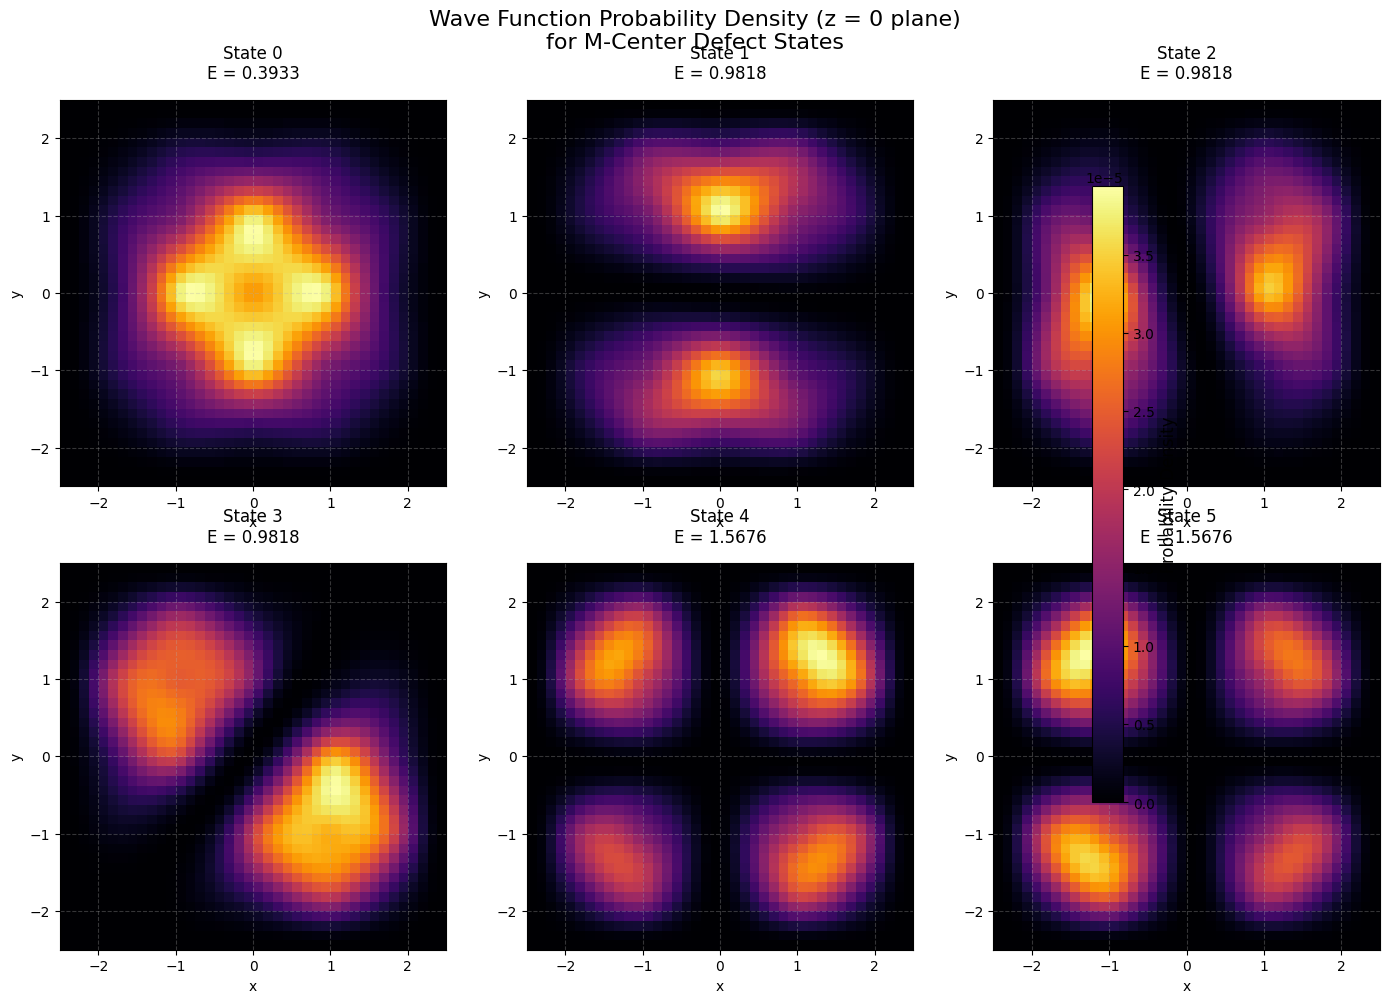


Dipole moments of transverse states:
--------------------------------------------------
State 2:
  <x> = 0.000000
  <y> = 0.000000
  <z> = -0.000000
  Total dipole magnitude = 0.000000
--------------------------------------------------
State 3:
  <x> = -0.000000
  <y> = 0.000000
  <z> = 0.000000
  Total dipole magnitude = 0.000000
--------------------------------------------------


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import eigsh

# ============================
# Параметры модели
# ============================
a = 1.0
q = 1.0
delta = 0.2

Nx = Ny = Nz = 40
L = 5 * a

x = np.linspace(-L/2, L/2, Nx)
y = np.linspace(-L/2, L/2, Ny)
z = np.linspace(-L/2, L/2, Nz)
h = x[1] - x[0]

# ============================
# Ионная решётка
# ============================
def generate_ionic_lattice(n_cells=3):
    ions = []
    for i in range(-n_cells, n_cells+1):
        for j in range(-n_cells, n_cells+1):
            for k in range(-n_cells, n_cells+1):
                r = np.array([i, j, k]) * a
                if (i + j + k) % 2 == 0:
                    ions.append((r, +q))
                else:
                    ions.append((r, -q))
    return ions

ions = generate_ionic_lattice()

vac1 = np.array([0, 0, 0])
vac2 = np.array([a, a, 0])

def is_vacancy(r):
    return np.allclose(r, vac1) or np.allclose(r, vac2)

ions_defect = []
for r, charge in ions:
    if charge < 0 and is_vacancy(r):
        continue
    ions_defect.append((r, charge))

# ============================
# Потенциал
# ============================
V = np.zeros((Nx, Ny, Nz))

for ix, X in enumerate(x):
    for iy, Y in enumerate(y):
        for iz, Z in enumerate(z):
            R = np.array([X, Y, Z])
            pot = 0.0
            for r_ion, q_ion in ions_defect:
                d = np.linalg.norm(R - r_ion)
                pot += q_ion / np.sqrt(d*d + delta*delta)
            V[ix, iy, iz] = pot

# ============================
# Гамильтониан
# ============================
def idx(i, j, k):
    return i + Nx * (j + Ny * k)

N = Nx * Ny * Nz
H = lil_matrix((N, N))

coef = 1.0 / h**2

for i in range(1, Nx-1):
    for j in range(1, Ny-1):
        for k in range(1, Nz-1):
            p = idx(i, j, k)
            H[p, p] = 3 * coef + V[i, j, k]
            H[p, idx(i+1, j, k)] = -0.5 * coef
            H[p, idx(i-1, j, k)] = -0.5 * coef
            H[p, idx(i, j+1, k)] = -0.5 * coef
            H[p, idx(i, j-1, k)] = -0.5 * coef
            H[p, idx(i, j, k+1)] = -0.5 * coef
            H[p, idx(i, j, k-1)] = -0.5 * coef

H = csr_matrix(H)

# ============================
# Собственные состояния
# ============================
n_states = 6
energies, states = eigsh(H, k=n_states, which='SA')

print("Eigenenergies:")
for i, E in enumerate(energies):
    print(f"{i}: {E:.6f}")

# ============================
# Визуализация: 2 × 3
# ============================
# Увеличим размер фигуры для лучшей читаемости
fig, axes = plt.subplots(2, 3, figsize=(14, 10))

# Настройка расстояний между субплогами
plt.subplots_adjust(hspace=0.35, wspace=0.3)

for n in range(n_states):
    ax = axes[n // 3, n % 3]

    psi3d = states[:, n].reshape((Nx, Ny, Nz))
    mid = Nz // 2
    prob_density = psi3d[:, :, mid]**2

    im = ax.imshow(
        prob_density,
        origin='lower',
        cmap='inferno',
        extent=[-L/2, L/2, -L/2, L/2]
    )

    # Улучшаем заголовки: добавляем перенос строки и отступ
    ax.set_title(f'State {n}\nE = {energies[n]:.4f}', fontsize=12, pad=15)
    ax.set_xlabel('x', fontsize=10)
    ax.set_ylabel('y', fontsize=10)
    
    # Добавляем сетку для наглядности
    ax.grid(True, alpha=0.3, linestyle='--')

# Цветовая шкала для всей фигуры
cbar = fig.colorbar(im, ax=axes.ravel().tolist(), 
                   shrink=0.8, pad=0.02)
cbar.set_label('Probability Density', fontsize=12)

# Общий заголовок
fig.suptitle('Wave Function Probability Density (z = 0 plane)\nfor M-Center Defect States', 
             fontsize=16, y=0.98)

plt.tight_layout()
plt.show()

# ============================
# Дипольные моменты
# ============================
def dipole_expectation(psi, axis):
    psi3d = psi.reshape((Nx, Ny, Nz))
    if axis == 'x':
        coord = x[:, None, None]
    elif axis == 'y':
        coord = y[None, :, None]
    else:
        coord = z[None, None, :]
    return np.sum(coord * psi3d**2)

print("\nDipole moments of transverse states:")
print("-" * 50)
for n in [2, 3]:
    dx = dipole_expectation(states[:, n], 'x')
    dy = dipole_expectation(states[:, n], 'y')
    dz = dipole_expectation(states[:, n], 'z')
    print(f"State {n}:")
    print(f"  <x> = {dx:.6f}")
    print(f"  <y> = {dy:.6f}")
    print(f"  <z> = {dz:.6f}")
    print(f"  Total dipole magnitude = {np.sqrt(dx**2 + dy**2 + dz**2):.6f}")
    print("-" * 50)

Eigenenergies:
0: 0.032148
1: 0.260744
2: 0.260744
3: 0.260744
4: 0.487767
5: 0.487767


C:\Users\Пользователь\AppData\Local\Temp\ipykernel_7912\3631134877.py:140: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


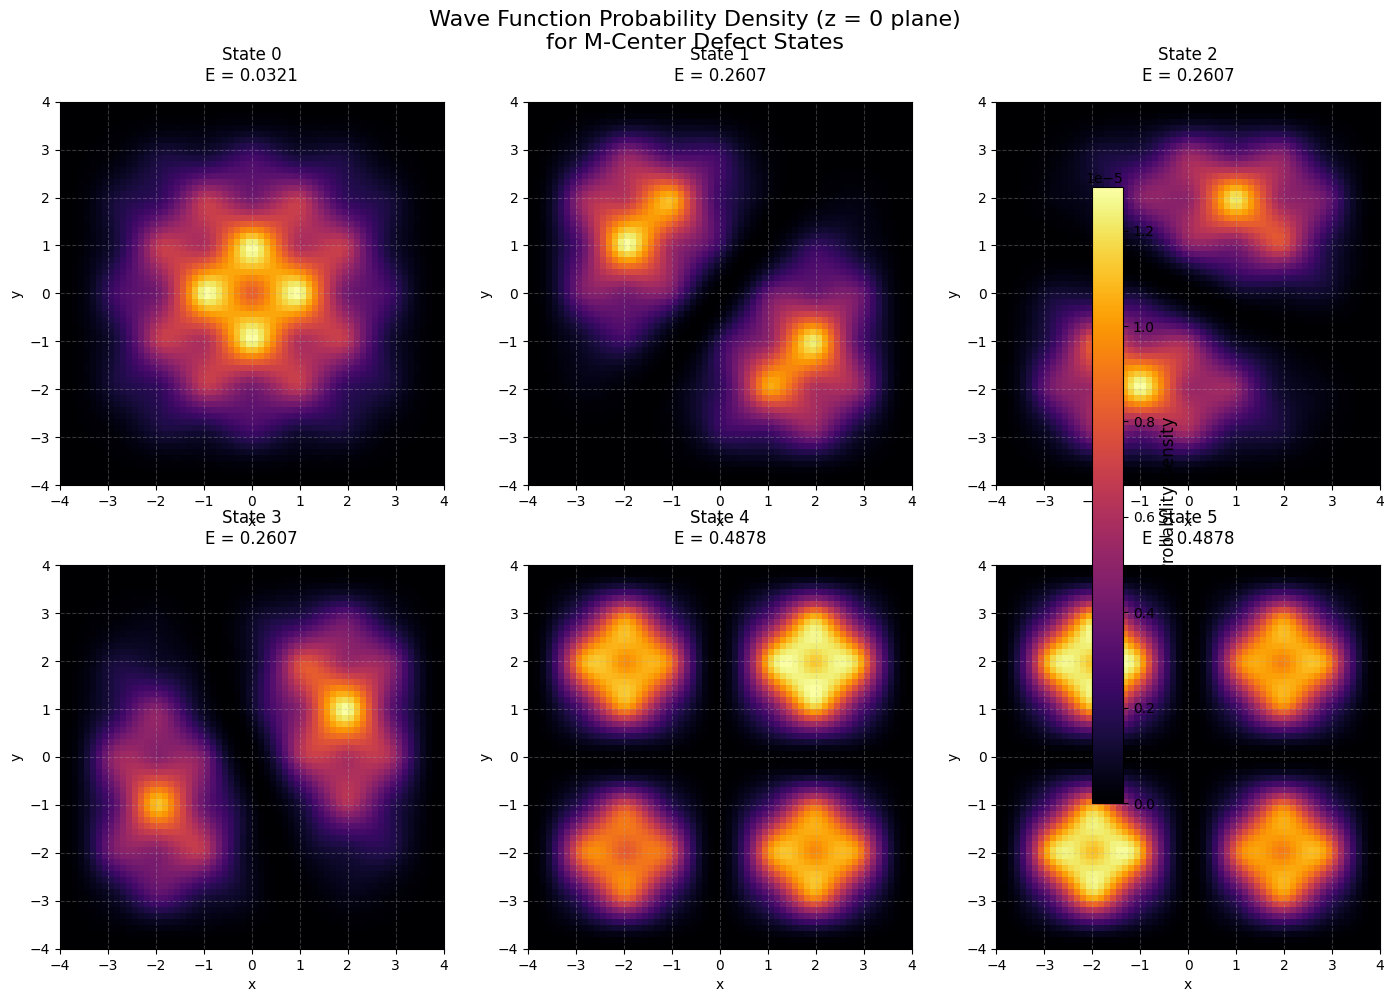


Dipole moments of transverse states:
--------------------------------------------------
State 2:
  <x> = -0.000000
  <y> = -0.000000
  <z> = 0.000000
  Total dipole magnitude = 0.000000
--------------------------------------------------
State 3:
  <x> = 0.000000
  <y> = 0.000000
  <z> = -0.000000
  Total dipole magnitude = 0.000000
--------------------------------------------------


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import eigsh

# ============================
# Параметры модели
# ============================
a = 1.0
q = 1.0
delta = 0.2

Nx = Ny = Nz = 64
L = 8 * a

x = np.linspace(-L/2, L/2, Nx)
y = np.linspace(-L/2, L/2, Ny)
z = np.linspace(-L/2, L/2, Nz)
h = x[1] - x[0]

# ============================
# Ионная решётка
# ============================
def generate_ionic_lattice(n_cells=8):
    ions = []
    for i in range(-n_cells, n_cells+1):
        for j in range(-n_cells, n_cells+1):
            for k in range(-n_cells, n_cells+1):
                r = np.array([i, j, k]) * a
                if (i + j + k) % 2 == 0:
                    ions.append((r, +q))
                else:
                    ions.append((r, -q))
    return ions

ions = generate_ionic_lattice()

vac1 = np.array([0, 0, 0])
vac2 = np.array([a, a, 0])

def is_vacancy(r):
    return np.allclose(r, vac1) or np.allclose(r, vac2)

ions_defect = []
for r, charge in ions:
    if charge < 0 and is_vacancy(r):
        continue
    ions_defect.append((r, charge))

# ============================
# Потенциал
# ============================
V = np.zeros((Nx, Ny, Nz))

for ix, X in enumerate(x):
    for iy, Y in enumerate(y):
        for iz, Z in enumerate(z):
            R = np.array([X, Y, Z])
            pot = 0.0
            for r_ion, q_ion in ions_defect:
                d = np.linalg.norm(R - r_ion)
                pot += q_ion / np.sqrt(d*d + delta*delta)
            V[ix, iy, iz] = pot

# ============================
# Гамильтониан
# ============================
def idx(i, j, k):
    return i + Nx * (j + Ny * k)

N = Nx * Ny * Nz
H = lil_matrix((N, N))

coef = 1.0 / h**2

for i in range(1, Nx-1):
    for j in range(1, Ny-1):
        for k in range(1, Nz-1):
            p = idx(i, j, k)
            H[p, p] = 3 * coef + V[i, j, k]
            H[p, idx(i+1, j, k)] = -0.5 * coef
            H[p, idx(i-1, j, k)] = -0.5 * coef
            H[p, idx(i, j+1, k)] = -0.5 * coef
            H[p, idx(i, j-1, k)] = -0.5 * coef
            H[p, idx(i, j, k+1)] = -0.5 * coef
            H[p, idx(i, j, k-1)] = -0.5 * coef

H = csr_matrix(H)

# ============================
# Собственные состояния
# ============================
n_states = 6
energies, states = eigsh(H, k=n_states, which='SA')

print("Eigenenergies:")
for i, E in enumerate(energies):
    print(f"{i}: {E:.6f}")

# ============================
# Визуализация: 2 × 3
# ============================
# Увеличим размер фигуры для лучшей читаемости
fig, axes = plt.subplots(2, 3, figsize=(14, 10))

# Настройка расстояний между субплогами
plt.subplots_adjust(hspace=0.5, wspace=0.3)

for n in range(n_states):
    ax = axes[n // 3, n % 3]

    psi3d = states[:, n].reshape((Nx, Ny, Nz))
    mid = Nz // 2
    prob_density = psi3d[:, :, mid]**2

    im = ax.imshow(
        prob_density,
        origin='lower',
        cmap='inferno',
        extent=[-L/2, L/2, -L/2, L/2]
    )

    # Улучшаем заголовки: добавляем перенос строки и отступ
    ax.set_title(f'State {n}\nE = {energies[n]:.4f}', fontsize=12, pad=15)
    ax.set_xlabel('x', fontsize=10)
    ax.set_ylabel('y', fontsize=10)
    
    # Добавляем сетку для наглядности
    ax.grid(True, alpha=0.3, linestyle='--')

# Цветовая шкала для всей фигуры
cbar = fig.colorbar(im, ax=axes.ravel().tolist(), 
                   shrink=0.8, pad=0.02)
cbar.set_label('Probability Density', fontsize=12)

# Общий заголовок
fig.suptitle('Wave Function Probability Density (z = 0 plane)\nfor M-Center Defect States', 
             fontsize=16, y=0.98)

plt.tight_layout()
plt.show()

# ============================
# Дипольные моменты
# ============================
def dipole_expectation(psi, axis):
    psi3d = psi.reshape((Nx, Ny, Nz))
    if axis == 'x':
        coord = x[:, None, None]
    elif axis == 'y':
        coord = y[None, :, None]
    else:
        coord = z[None, None, :]
    return np.sum(coord * psi3d**2)

print("\nDipole moments of transverse states:")
print("-" * 50)
for n in [2, 3]:
    dx = dipole_expectation(states[:, n], 'x')
    dy = dipole_expectation(states[:, n], 'y')
    dz = dipole_expectation(states[:, n], 'z')
    print(f"State {n}:")
    print(f"  <x> = {dx:.6f}")
    print(f"  <y> = {dy:.6f}")
    print(f"  <z> = {dz:.6f}")
    print(f"  Total dipole magnitude = {np.sqrt(dx**2 + dy**2 + dz**2):.6f}")
    print("-" * 50)

Calculating potential...
Building Hamiltonian...
Solving eigensystem...

Correct Eigenenergies (must be negative):
State 0: -1.15507
State 1: -0.53340
State 2: -0.39891
State 3: -0.39770
State 4: -0.20741
State 5: -0.03849


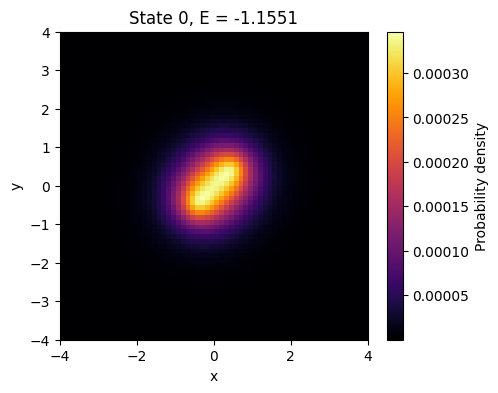

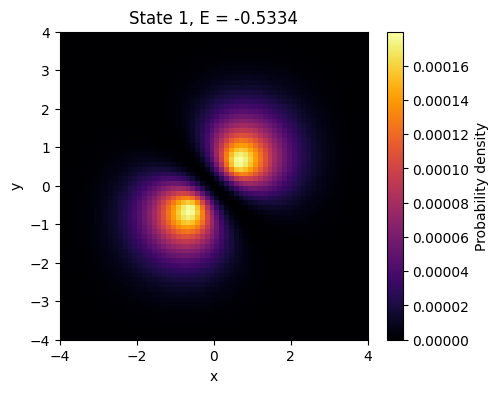

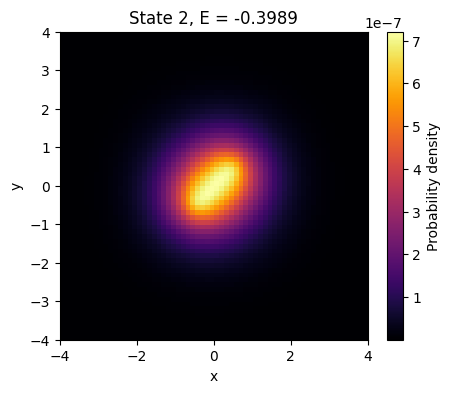

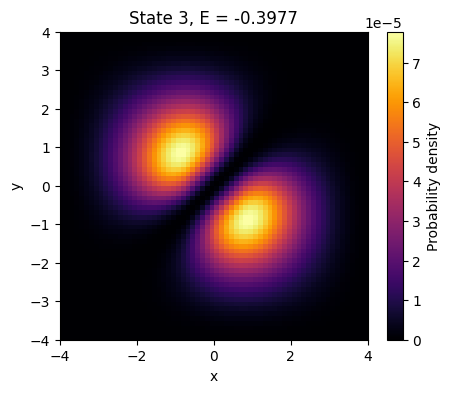

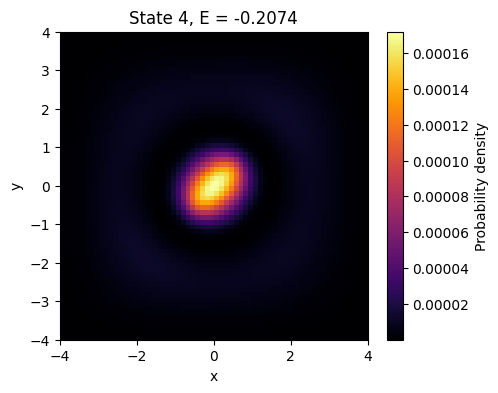

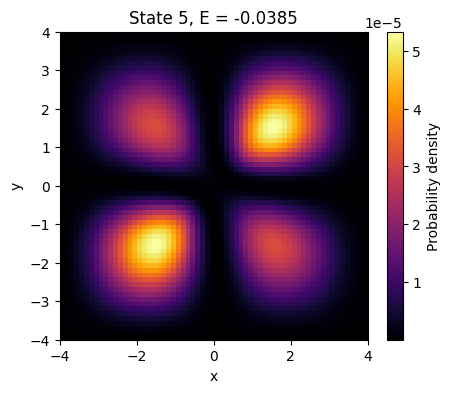


Dipole moments check (State 0 vs State 1):
State 0 center: x=4.000, y=4.000
State 1 center: x=4.000, y=4.000
State 2 center: x=4.000, y=4.000
State 3 center: x=4.000, y=4.000


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import eigsh

# --- ПАРАМЕТРЫ ---
a = 1.0
q_eff = 1.0       # Эффективный заряд вакансии (была -1, убрали -> стала +1)
delta = 0.2       # Параметр сглаживания (чтобы не делить на 0)

# Сетка и коробка
Nx = Ny = Nz = 64
L = 8.0 * a       # Размер ящика

x = np.linspace(-L/2, L/2, Nx)
y = np.linspace(-L/2, L/2, Ny)
z = np.linspace(-L/2, L/2, Nz)
h = x[1] - x[0]

# --- ГЕОМЕТРИЯ ДЕФЕКТА ---
# Вместо всей решетки определяем только центры притяжения
vac1 = np.array([-a/2, -a/2, 0]) # Сдвинем к центру для симметрии
vac2 = np.array([ a/2,  a/2, 0])

def get_potential_grid():
    """Считаем потенциал только от двух притягивающих центров"""
    V = np.zeros((Nx, Ny, Nz))

    # Чтобы ускорить, используем meshgrid (векторизация)
    Y, X, Z = np.meshgrid(y, x, z) # Обратите внимание на порядок в numpy

    # Расстояние до первой вакансии
    dist1 = np.sqrt((X - vac1[0])**2 + (Y - vac1[1])**2 + (Z - vac1[2])**2)
    # Расстояние до второй вакансии
    dist2 = np.sqrt((X - vac2[0])**2 + (Y - vac2[1])**2 + (Z - vac2[2])**2)

    # Потенциальная энергия электрона U = -e * phi.
    # Вакансия заряжена положительно (+q_eff). Потенциал phi > 0.
    # Электрон (-1) притягивается. Значит энергия должна быть ОТРИЦАТЕЛЬНОЙ.
    # Формула: -1 * (+q) / r

    V = -q_eff / np.sqrt(dist1**2 + delta**2) \
        -q_eff / np.sqrt(dist2**2 + delta**2)

    return V

print("Calculating potential...")
V = get_potential_grid()

# --- ГАМИЛЬТОНИАН ---
print("Building Hamiltonian...")
N = Nx * Ny * Nz
H = lil_matrix((N, N))
coef = 1.0 / h**2 # Кинетический член -1/2 * nabla^2 -> коэфф 0.5/h^2

# Векторизованная сборка диагонали сильно ускорит процесс,
# но для наглядности оставим цикл (или используем diags для скорости, если умеете)
# Оставим ваш цикл, но он медленный для Python.
# НО! Для 64^3 точек цикл Python будет заполняться минуту.
# Ускорим сборку через массивы:

from scipy.sparse import diags, kron, eye

# Строим Лапласиан через кронекеровские произведения (гораздо быстрее циклов)
# D2 - вторая производная для 1D
ones = np.ones(Nx)
D2_x = diags([-0.5*ones[1:], 1.0*ones, -0.5*ones[1:]], [-1, 0, 1], shape=(Nx, Nx)) / h**2
I = eye(Nx)

# Лапласиан в 3D = Dxx + Dyy + Dzz
# L = D2 (x) I (x) I + I (x) D2 (x) I + I (x) I (x) D2
L3 = kron(kron(D2_x, I), I) + kron(kron(I, D2_x), I) + kron(I, kron(I, D2_x))

# Потенциал на диагонали
V_diag = diags(V.flatten(), 0)

H = L3 + V_diag # H = T + V
# Заметка: в вашем коде на диагонали было 3*coef.
# В матрице D2_x на диагонали стоит +1.0/h^2 (потому что -0.5*(-2)).
# Сумма трех таких даст 3.0/h^2. Всё верно.

print("Solving eigensystem...")
n_states = 6
energies, states = eigsh(H, k=n_states, which='SA') # SA = Smallest Algebraic (самые отрицательные)

print("\nCorrect Eigenenergies (must be negative):")
for i, E in enumerate(energies):
    print(f"State {i}: {E:.5f}")

# --- ВИЗУАЛИЗАЦИЯ ---
def plot_slice(psi, title):
    psi3d = psi.reshape((Nx, Ny, Nz))
    mid = Nz // 2
    plt.figure(figsize=(5,4))
    plt.imshow(psi3d[:, :, mid]**2, origin='lower', extent=[-L/2, L/2, -L/2, L/2], cmap='inferno')
    plt.colorbar(label='Probability density')
    plt.title(title)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.show()

for n in range(6):
    plot_slice(states[:, n], f"State {n}, E = {energies[n]:.4f}")

# --- ДИПОЛЬНЫЕ МОМЕНТЫ ---
print("\nDipole moments check:")
# State 0 (bonding) должен быть симметричным (диполь 0)
# State 1 (antibonding) антисимметричным по плотности? Нет, |psi|^2 симметричен.
# Интереснее посмотреть перекрытия или средние координаты.

def get_avg_pos(psi):
    psi3d = psi.reshape((Nx, Ny, Nz))
    dens = psi3d**2
    norm = np.sum(dens)
    x_avg = np.sum(X * dens) / norm
    y_avg = np.sum(Y * dens) / norm
    return x_avg, y_avg

for n in range(4):
    ax, ay = get_avg_pos(states[:, n])
    print(f"State {n} center: x={ax:.3f}, y={ay:.3f}")

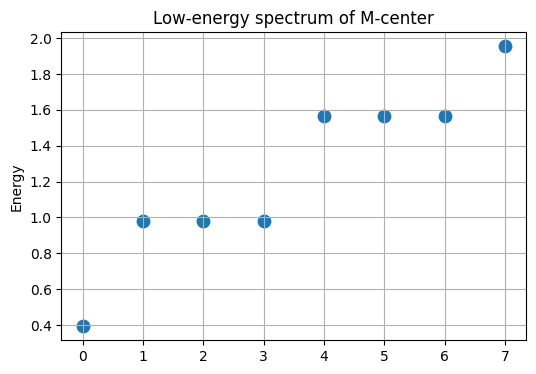

Eigenenergies:
0: 0.393300
1: 0.981792
2: 0.981792
3: 0.981792
4: 1.567602
5: 1.567602
6: 1.567602
7: 1.954771


C:\Users\Пользователь\AppData\Local\Temp\ipykernel_7912\2832560807.py:122: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


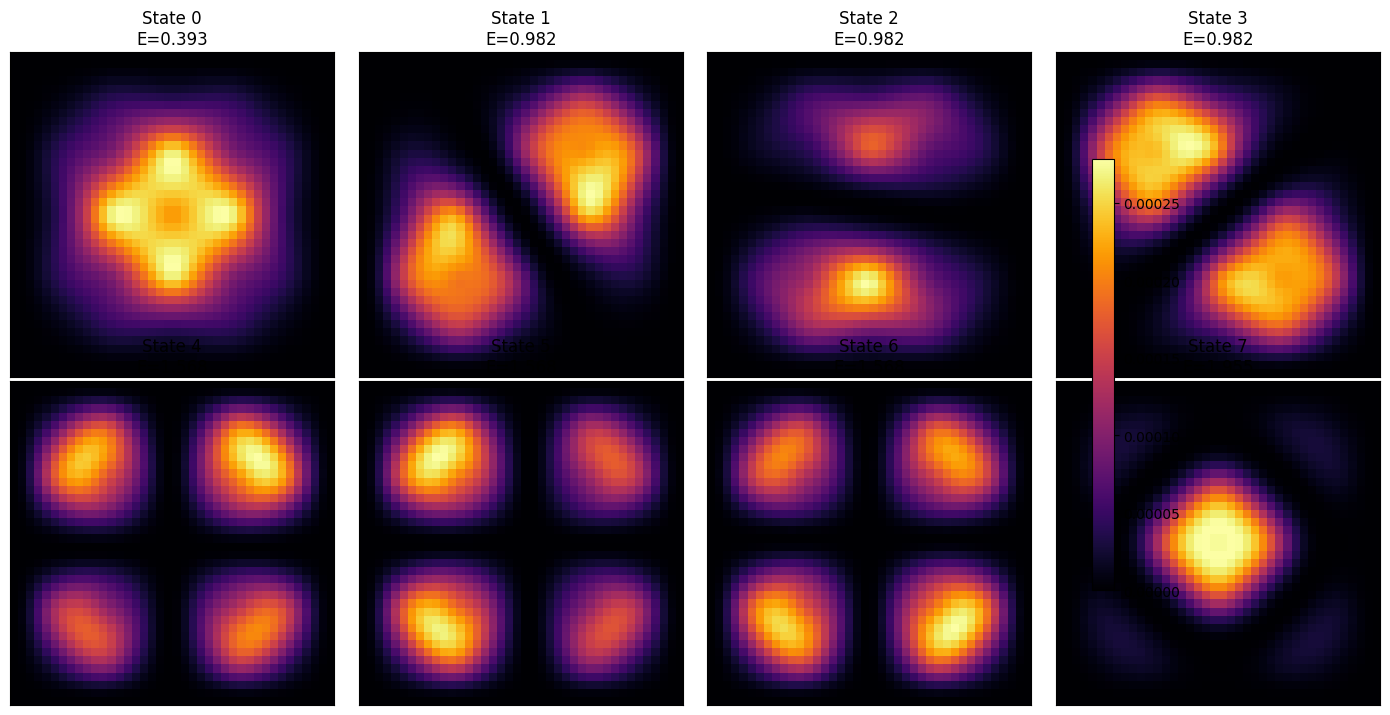


Dipole moments (p-state diagnostics):
State 1: <x>=-0.000, <y>=-0.000, <z>=-0.000
State 2: <x>=-0.000, <y>=-0.000, <z>=0.000
State 3: <x>=0.000, <y>=0.000, <z>=-0.000
State 4: <x>=-0.000, <y>=0.000, <z>=0.000


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import eigsh

# ============================
# Параметры
# ============================
a = 1.0
q = 1.0
delta = 0.2

Nx = Ny = Nz = 40
L = 5 * a

x = np.linspace(-L/2, L/2, Nx)
y = np.linspace(-L/2, L/2, Ny)
z = np.linspace(-L/2, L/2, Nz)
h = x[1] - x[0]

# ============================
# Ионная решётка
# ============================
def generate_ionic_lattice(n_cells=3):
    ions = []
    for i in range(-n_cells, n_cells+1):
        for j in range(-n_cells, n_cells+1):
            for k in range(-n_cells, n_cells+1):
                r = np.array([i, j, k]) * a
                charge = +q if (i + j + k) % 2 == 0 else -q
                ions.append((r, charge))
    return ions

ions = generate_ionic_lattice()

# M-центр: две вакансии
vac1 = np.array([0, 0, 0])
vac2 = np.array([a, a, 0])

def is_vacancy(r):
    return np.allclose(r, vac1) or np.allclose(r, vac2)

ions_defect = []
for r, charge in ions:
    if charge < 0 and is_vacancy(r):
        continue
    ions_defect.append((r, charge))

# ============================
# Потенциал
# ============================
V = np.zeros((Nx, Ny, Nz))

for ix, X in enumerate(x):
    for iy, Y in enumerate(y):
        for iz, Z in enumerate(z):
            R = np.array([X, Y, Z])
            pot = 0.0
            for r_ion, q_ion in ions_defect:
                d = np.linalg.norm(R - r_ion)
                pot += q_ion / np.sqrt(d*d + delta*delta)
            V[ix, iy, iz] = pot

# ============================
# Гамильтониан
# ============================
def idx(i, j, k):
    return i + Nx * (j + Ny * k)

N = Nx * Ny * Nz
H = lil_matrix((N, N))

coef = 1.0 / h**2

for i in range(1, Nx-1):
    for j in range(1, Ny-1):
        for k in range(1, Nz-1):
            p = idx(i, j, k)
            H[p, p] = 3 * coef + V[i, j, k]
            for di, dj, dk in [(1,0,0),(-1,0,0),(0,1,0),(0,-1,0),(0,0,1),(0,0,-1)]:
                H[p, idx(i+di, j+dj, k+dk)] = -0.5 * coef

H = csr_matrix(H)

# ============================
# Собственные значения
# ============================
n_states = 8
energies, states = eigsh(H, k=n_states, which='SA')

# ============================
# Спектр (ГЛАВНОЕ)
# ============================
plt.figure(figsize=(6, 4))
plt.scatter(range(n_states), energies, s=80)
plt.xticks(range(n_states))
plt.ylabel("Energy")
plt.title("Low-energy spectrum of M-center")
plt.grid(True)
plt.show()

print("Eigenenergies:")
for i, E in enumerate(energies):
    print(f"{i}: {E:.6f}")

# ============================
# Визуализация плотностей
# ============================
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for n in range(n_states):
    ax = axes[n // 4, n % 4]
    psi3d = states[:, n].reshape((Nx, Ny, Nz))
    mid = Nz // 2

    im = ax.imshow(psi3d[:, :, mid]**2, cmap='inferno', origin='lower')
    ax.set_title(f"State {n}\nE={energies[n]:.3f}")
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8)
plt.tight_layout()
plt.show()

# ============================
# Диагностика p-орбиталей
# ============================
def dipole(psi, axis):
    psi3d = psi.reshape((Nx, Ny, Nz))
    if axis == 'x':
        coord = x[:, None, None]
    elif axis == 'y':
        coord = y[None, :, None]
    else:
        coord = z[None, None, :]
    return np.sum(coord * psi3d**2)

print("\nDipole moments (p-state diagnostics):")
for n in range(1, 5):
    dx = dipole(states[:, n], 'x')
    dy = dipole(states[:, n], 'y')
    dz = dipole(states[:, n], 'z')
    print(f"State {n}: <x>={dx:.3f}, <y>={dy:.3f}, <z>={dz:.3f}")
